In [1]:
import tensorflow as tf
from tensorflow.keras.models import load_model
import numpy as np
import matplotlib.pyplot as plt
import os

2026-07-05 15:13:31.201304: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783257211.219394   34569 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783257211.224842   34569 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-07-05 15:13:31.244189: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
MODEL_PATH = 'generator.keras'
generator = load_model(MODEL_PATH, compile=False)

I0000 00:00:1783257402.824535   34569 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 112 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1070, pci bus id: 0000:01:00.0, compute capability: 6.1


In [4]:
IMG_SIZE = (192, 192)

In [5]:
def preprocess_image_tf(image_path):
        raw_image = tf.io.read_file(image_path)
        color_image = tf.io.decode_image(raw_image, channels=3)
        color_image = tf.image.resize(color_image, [IMG_SIZE[0], IMG_SIZE[1]])
        color_image = tf.cast(color_image, tf.float32)
        normalized_color = (color_image - 127.5) / 127.5
        normalized_color_batch = tf.expand_dims(normalized_color, 0)
        grayscale_image = tf.image.rgb_to_grayscale(normalized_color_batch)

        return grayscale_image, normalized_color

In [12]:
IMAGE_PATH = 'image.JPEG'

In [13]:
input_grayscale, original_color = preprocess_image_tf(IMAGE_PATH)

In [14]:
generated_image = generator.predict(input_grayscale)

I0000 00:00:1783257669.374362   34792 service.cc:148] XLA service 0x70cf4000f7a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1783257669.374396   34792 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce GTX 1070, Compute Capability 6.1
2026-07-05 15:21:09.387202: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1783257669.457161   34792 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-07-05 15:21:09.598569: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran out of memory trying to allocate 16.56MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
2026-07-05 15:21:09.598630: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:306] Allocator (GPU_0_bfc) ran ou

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 949ms/step


I0000 00:00:1783257670.084280   34792 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


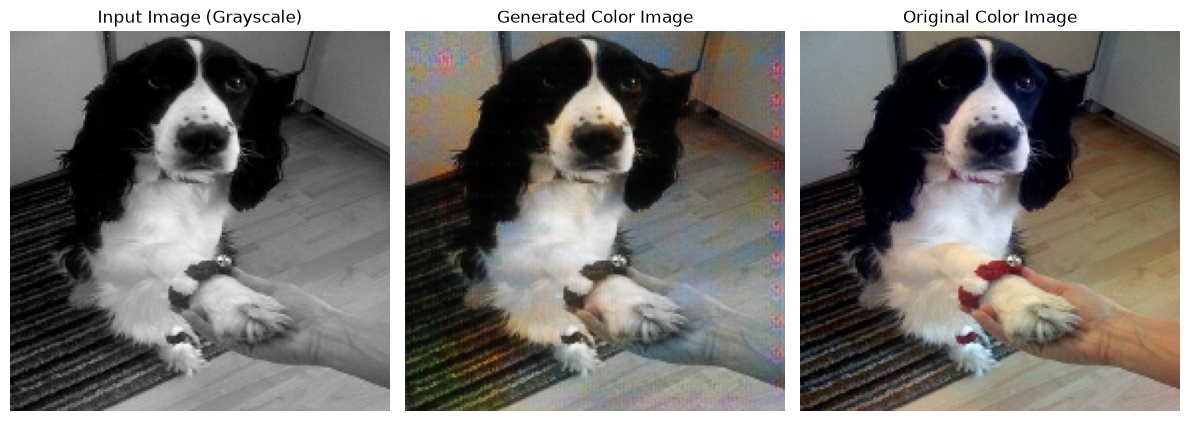

In [15]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.title("Input Image (Grayscale)")
plt.imshow(input_grayscale[0, ..., 0], cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Generated Color Image")
plt.imshow(generated_image[0] * 0.5 + 0.5)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Original Color Image")
plt.imshow(original_color * 0.5 + 0.5)
plt.axis('off')

plt.tight_layout()
plt.show()